# **Aprendizado _Online_: Adaptação a Drifts em Demanda de Energia**
<font size=3>

O comportamento do consumo de energia não é estático. Ele muda drasticamente dependendo do clima, do dia da semana ou de feriados. Esses fenômenos geram o que chamamos de **_Concept Drift_** (mudança de conceito). Modelos de aprendizado *online* precisam se ajustar rapidamente a essas transições temporais.

Nesta abordagem, o modelo entra em um jogo sequencial com o Ambiente. Diferente do aprendizado em lote (*batch*), aplicaremos a **Avaliação Prequencial**: a cada novo dia, o modelo primeiro prevê a demanda usando o que sabe e, logo em seguida, o Ambiente revela a demanda real para que ele atualize seus pesos.

In [ ]:
!pip install river kagglehub -q

In [ ]:
import kagglehub
import pandas as pd
import matplotlib.pyplot as plt
from river import compose, preprocessing, tree, metrics, utils, stream

# 1. Download e Carregamento do Dataset
path = kagglehub.dataset_download("rohitgrewal/electricity-demand-data-dsl")
csv_file = f"{path}/python machine learning model xgboost - electricity demand dataset.csv"

df = pd.read_csv(csv_file)

# Visão geral das primeiras linhas do dataset para entender a estrutura
print("Visão geral das primeiras linhas do dataset:")
display(df.head())

# Resumo estatístico das variáveis
print("\nResumo estatístico das variáveis:")
display(df.describe())

# Verificando se há valores nulos (dados faltantes)
print("\nVerificando valores nulos:")
display(df.isnull().sum())

# Extraindo as features que representam as transições climáticas e temporais
features = ['hour', 'dayofweek', 'month', 'Temperature', 'Humidity']
target = 'Demand'

# O River trabalha com dicionários fluindo sequencialmente (streaming)
X_y = stream.iter_pandas(df[features], df[target])

100%|██████████| 945k/945k [00:00<00:00, 85.3MB/s]

Extracting files...
Visão geral das primeiras linhas do dataset:


,Timestamp,hour,dayofweek,month,year,dayofyear,Temperature,Humidity,Demand
0,01-Jan-20,0.0,2.0,1.0,2020.0,1.0,3.000000,61.288951,2457.119872
1,01-Jan-20,1.0,2.0,1.0,2020.0,1.0,3.000000,52.873702,2269.904712
2,01-Jan-20,2.0,2.0,1.0,2020.0,1.0,4.244482,36.341783,2215.640403
3,01-Jan-20,3.0,2.0,1.0,2020.0,1.0,3.000000,72.629378,2174.232413
4,01-Jan-20,4.0,2.0,1.0,2020.0,1.0,3.881208,90.582444,2472.453006



Resumo estatístico das variáveis:


,hour,dayofweek,month,year,dayofyear,Temperature,Humidity,Demand
count,43837.000000,43839.000000,43840.000000,43843.000000,43843.000000,43841.000000,43838.000000,43841.000000
mean,11.499030,2.999795,6.521282,2022.000068,183.208654,25.067788,59.903007,5000.790976
std,6.922006,2.000051,3.449168,1.415044,105.478826,12.821725,18.342604,1412.527409
min,0.000000,0.000000,1.000000,2020.000000,1.000000,3.000000,20.000000,1611.954020
25%,5.000000,1.000000,4.000000,2021.000000,92.000000,15.210186,46.241224,4015.668472
50%,11.000000,3.000000,7.000000,2022.000000,183.000000,25.003212,59.986720,5013.053367
75%,17.000000,5.000000,10.000000,2023.000000,275.000000,34.740971,73.796820,6000.803082
max,23.000000,6.000000,12.000000,2024.000000,366.000000,50.000000,95.000000,11910.705100



Verificando valores nulos:


,0
Timestamp,0
hour,11
dayofweek,9
month,8
year,5
dayofyear,5
Temperature,7
Humidity,10
Demand,7


## **1. Modelagem Dinâmica e Janela Deslizante**
<font size=3>
    
Para lidar com as flutuações, utilizaremos uma **Árvore de Decisão Adaptativa de Hoeffding (HAT Regressor)**. Esta estrutura é excelente para dados contínuos pois possui detectores internos de *drift* que cortam ramos desatualizados e ramificam novos caminhos conforme o clima ou o dia da semana mudam.

Na avaliação, descartamos a média acumulada global, pois ela mascara a realidade atual. Avaliaremos a performance usando uma **Janela Deslizante** (*Sliding Window*) com o Erro Absoluto Médio (Rolling MAE) ajustado para as últimas 7 instâncias (exatamente 1 semana).

Iniciando a Avaliação Prequencial (Dia a Dia)...
Rolling MAE final: 248.81 MW


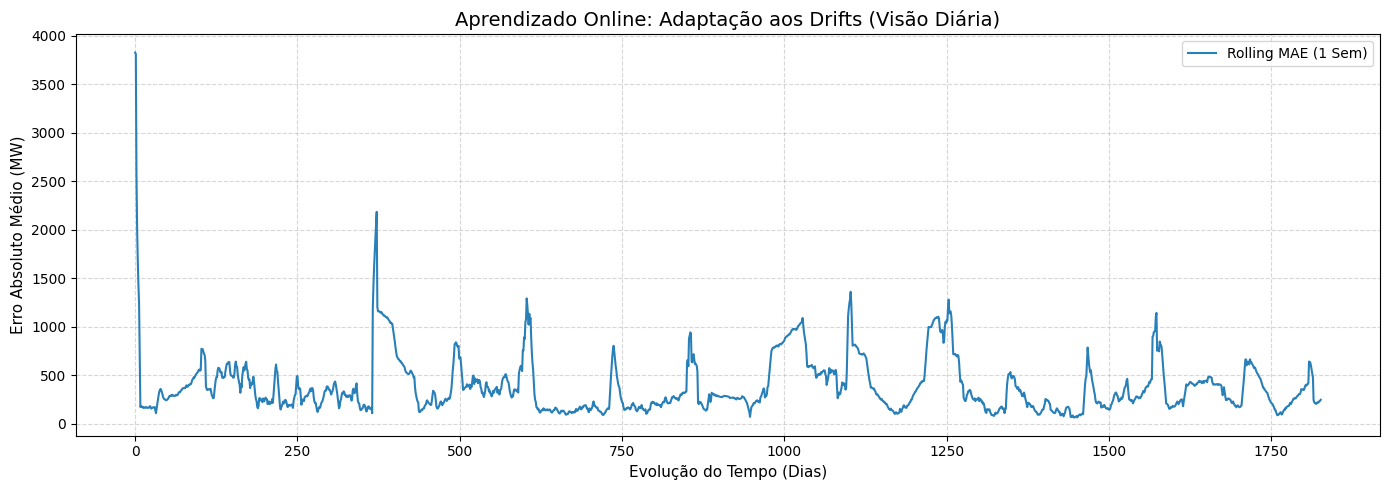

In [ ]:
import sys

# 1. Transformar Hora em Dia (Média diária) ignorando as colunas de texto
df_diario = df.groupby(['year', 'dayofyear'], sort=False).mean(numeric_only=True).reset_index()
df_diario = df_diario.round(2)

# Features retiradas: ['hour', 'Timestamp']
features_diarias = ['dayofweek', 'month', 'Temperature', 'Humidity']
target = 'Demand'

X_y = stream.iter_pandas(df_diario[features_diarias], df_diario[target])

# 2. Construção do Pipeline
modelo = compose.Pipeline(
    preprocessing.StandardScaler(),
    tree.HoeffdingAdaptiveTreeRegressor(grace_period=50, max_depth=15)
)

# Métrica de Janela: agora 7 instâncias equivalem a 1 semana exata
metrica = utils.Rolling(metrics.MAE(), window_size=7)
erros_temporais = []

print("Iniciando a Avaliação Prequencial (Dia a Dia)...")

# 3. Loop Sequencial
for i, (x, y) in enumerate(X_y):
    y_pred = modelo.predict_one(x)

    if y_pred is not None:
        metrica.update(y_true=y, y_pred=y_pred)

    # Registramos o erro a cada nova instância (1 dia)
    erros_temporais.append(metrica.get())

    modelo.learn_one(x, y)

print(f"Rolling MAE final: {metrica.get():.2f} MW")

# 4. Visualização
plt.figure(figsize=(14, 5))
plt.plot(erros_temporais, label='Rolling MAE (1 Sem)', color='#2980b9', linewidth=1.5)
plt.title('Aprendizado Online: Adaptação aos Drifts (Visão Diária)', fontsize=14)
plt.xlabel('Evolução do Tempo (Dias)', fontsize=11)
plt.ylabel('Erro Absoluto Médio (MW)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

## **Comparação de Modelos _Online_**

Para avaliar diferentes estratégias de adaptação aos *drifts* climáticos e temporais, compararemos três algoritmos apresentados na disciplina:

1. **Hoeffding Adaptive Tree (HAT):** Árvore rápida com mecanismo de poda de galhos obsoletos.
2. **KNN Online:** Trabalha com "janela deslizante" (memória curta), o que garante adaptação muito rápida a mudanças abruptas.
3. **Adaptive Random Forest (ARF):** Uma floresta de árvores adaptativas (*ensemble*), considerada o estado da arte em estabilidade e acurácia.

Iniciando o Treinamento Comparativo (Isso pode levar alguns segundos)...
Rolling MAE final (Hoeffding Tree (HAT)): 455.59 MW
Rolling MAE final (KNN Online): 19.12 MW
Rolling MAE final (Adaptive Random Forest (ARF)): 68.52 MW


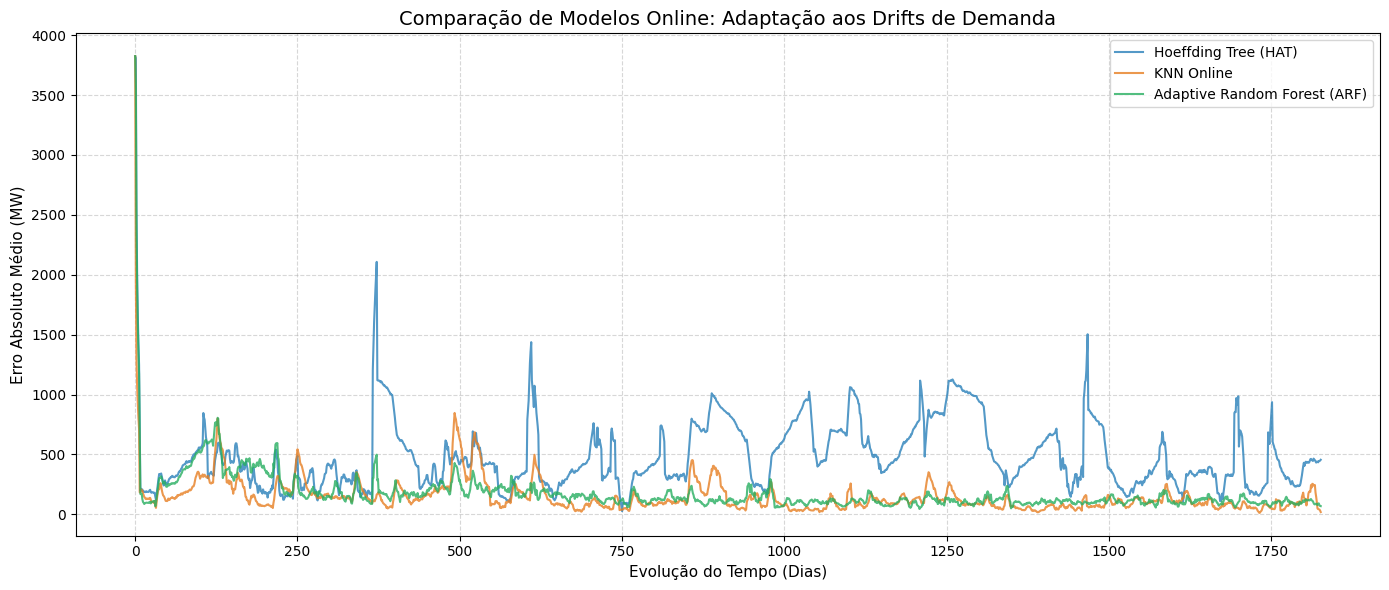

In [ ]:
from river import forest, neighbors

# 1. Definindo os 3 Modelos
modelos = {
    "Hoeffding Tree (HAT)": compose.Pipeline(
        preprocessing.StandardScaler(),
        tree.HoeffdingAdaptiveTreeRegressor(grace_period=50, max_depth=15)
    ),
    "KNN Online": compose.Pipeline(
        preprocessing.StandardScaler(),
        neighbors.KNNRegressor(n_neighbors=7)
    ),
    "Adaptive Random Forest (ARF)": compose.Pipeline(
        preprocessing.StandardScaler(),
        forest.ARFRegressor(n_models=10, seed=42)
    )
}

# 2. Configurando o fluxo de dados e métricas separadas
X_y = stream.iter_pandas(df_diario[features_diarias], df_diario[target])

metricas = {nome: utils.Rolling(metrics.MAE(), window_size=7) for nome in modelos}
erros_temporais = {nome: [] for nome in modelos}

print("Iniciando o Treinamento Comparativo (Isso pode levar alguns segundos)...")

# 3. Loop Prequencial Simultâneo
for i, (x, y) in enumerate(X_y):
    for nome, modelo in modelos.items():
        # Previsão
        y_pred = modelo.predict_one(x)

        # Avaliação
        if y_pred is not None:
            metricas[nome].update(y_true=y, y_pred=y_pred)

        # Registro do erro
        erros_temporais[nome].append(metricas[nome].get())

        # Aprendizado
        modelo.learn_one(x, y)

# 4. Visualização Comparativa
plt.figure(figsize=(14, 6))
cores = {'Hoeffding Tree (HAT)': '#2980b9', 'KNN Online': '#e67e22', 'Adaptive Random Forest (ARF)': '#27ae60'}

for nome in modelos:
    print(f"Rolling MAE final ({nome}): {metricas[nome].get():.2f} MW")
    plt.plot(erros_temporais[nome], label=nome, color=cores[nome], linewidth=1.5, alpha=0.8)

plt.title('Comparação de Modelos Online: Adaptação aos Drifts de Demanda', fontsize=14)
plt.xlabel('Evolução do Tempo (Dias)', fontsize=11)
plt.ylabel('Erro Absoluto Médio (MW)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

### **6. Comparativo entre Modelos**

A gente também rodou mais dois modelos pra comparar com a **Árvore de Hoeffding (HAT)**, que foram o **KNN Online** e a **Adaptive Random Forest (ARF)** pra ver quem se saía melhor lidando com essas mudanças bruscas de conceito na demanda de energia.

Olhando o gráfico, a gente vê que o **KNN Online** *(linha laranja)* acabou sendo o grande destaque na métrica final, fechando a série com o menor nível de erro de todos: impressionantes **19,12 MW**. Isso prova que, para o consumo de energia, uma técnica pautada em observar o passado imediato (os dias mais recentes e parecidos climaticamente) funciona muito bem, garantindo uma adaptação e recuperação extremamente rápida a variações repentinas.

A **Adaptive Random Forest** *(linha verde)* também se saiu muito bem e mostrou a força dos métodos de *ensemble*. Ela se manteve super estável ao longo de todo o período analisado e atingiu um excelente erro final de **68,52 MW**, mostrando-se uma opção muito robusta para manter a constância e evitar picos absurdos de erro ao longo do tempo.

Já a nossa **Árvore de Hoeffding** original *(linha azul)* foi a que mais sofreu no comparativo, alcançando um erro final de **455,59 MW** e apresentando picos gigantescos de erro ao longo dos dias. Isso evidencia que, por ser uma árvore solitária tentando se ajustar aos dados novos, ela se perde um pouco na matemática quando rola um *concept drift* mais brusco, demorando mais tempo antes de conseguir podar os galhos obsoletos e criar novas ramificações.

A conclusão final que a gente tira é que pra esse tipo de dado contínuo e sujeito a tantas mudanças, o **KNN Online** surpreendeu pela agilidade de resposta no curto prazo, enquanto a **Floresta Adaptativa** provou ser a mais estável a longo prazo, e árvores solitárias podem ser bem arriscadas se houver muita variação no ambiente.